# Simulación de Colas M/M/1 y M/H4/1 (M/G/1) — Parqueaderos Centro Comercial Supercentro

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Camilo-Alberto-Palacio/Simulacion-Parqueadero-Supercentro-MM1/blob/main/Simulacion_Parqueadero_Supercentro_Colab.ipynb)

---
### Institución Universitaria Digital de Antioquia (IU Digital)
* **Facultad:** Facultad de Ingeniería — Ingeniería de Software y Datos
* **Asignatura:** Simulación — `PREICA2602B020045` (Módulo 4 — Actividad Didáctica 2-M4)
* **Docente:** Dr. Julián Andrés Loaiza López
* **Grupo:** 25 · **Sede:** Medellín, Antioquia · **Fecha:** Noviembre de 2026

#### Integrantes del Equipo:
1. **Adriana Andrea Agudelo Agudelo**
2. **Camilo Alberto Palacios Turriago**
3. **Juan Daniel Pulgarin García**
4. **Ruben Dario Jaramillo Cervantes**

---

## 1. Contexto del Problema y Marco Teórico Exacto ($M/M/1$ vs. $M/H_4/1$)

Cada salida del parqueadero del **Centro Comercial Supercentro** opera actualmente con **3 cajeros automáticos independientes** bajo disciplina **FCFS** (*First-Come, First-Served*), sin cambio de fila ni deserción, sobre jornadas operativas de $1000\text{ minutos}$. Aunque cada perfil individual de conductor obedece un sistema exponencial $M/M/1$:

* **Rápido ($25.0\%$):** $E[S] = 1.0\text{ min}$, $E[IA] = 3.0\text{ min}$ ($\rho = 0.333$)
* **Normal ($20.0\%$):** $E[S] = 3.0\text{ min}$, $E[IA] = 3.0\text{ min}$ ($\rho = 1.000$ — límite inestable)
* **Lento ($27.5\%$):** $E[S] = 4.0\text{ min}$, $E[IA] = 5.0\text{ min}$ ($\rho = 0.800$)
* **Muy lento ($27.5\%$):** $E[S] = 6.0\text{ min}$, $E[IA] = 7.0\text{ min}$ ($\rho = 0.857$)

Al combinar los cuatro perfiles con igual probabilidad de entrada a cada cajero paralelo (ruteo base uniforme $1/c$), el tiempo de servicio resultante sigue una mezcla **hiperexponencial de orden 4 ($H_4$)** con $E[S] = 3.600\text{ min}$, $E[S^2] = 32.70\text{ min}^2$ y $C_s^2 = 1.5231 > 1$. Bajo proceso de llegadas Poisson homogéneo en la salida ($\lambda_{\text{salida}} = 3 / 4.650 = 0.6452\text{ veh/min}$), cada servidor mixto es exactamente una cola **$M/H_4/1$ ($M/G/1$)**, donde la fórmula de **Pollaczek–Khinchine** es una identidad exacta ($W_q^{\text{M/G/1}} = 15.57\text{ min}$ frente a la aproximación exponencial $W_q^{\text{M/M/1}} = 12.34\text{ min}$):
$$L_q^{\text{M/M/1}} = \frac{\rho^2}{1 - \rho}, \qquad L_q = \lambda_c\,W_q, \qquad W_q^{\text{M/M/1}} = \frac{\rho}{\mu_c(1 - \rho)}, \qquad W_q^{\text{M/G/1}} = \frac{\lambda_c\,\mathbb{E}[S^2]}{2(1 - \rho)}, \qquad W = W_q + \frac{1}{\mu_c}$$

Para los escenarios alternativos de diseño evaluamos: ampliación mixta (`E2..E4`), segregación especializada (`E5: 1E+3L` = 1 cajero Exprés para Rápido/Normal y 3 Estándar para Lento/Muy lento; `E6: 1E+4L` = 1 Exprés y 4 Estándar), actualización de software con reconocimiento de placa/QR (`E7: 4 Mix + UX/LPR`, $-25\%$ en servicio de Lentos y Muy lentos), señalización **JSQ** (*Join-the-Shortest-Queue*, elegir la fila visible más corta) y cola única serpentina **$M/G/c$**.

In [1]:
from collections import deque
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (13.6, 5.2)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.linestyle"] = ":"
plt.rcParams["grid.alpha"] = 0.6
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)

BASE_CASHIERS = 3
SIM_MINUTES = 1000.0
USER_TYPES = ["Rápido", "Normal", "Lento", "Muy lento"]
USER_TYPE_PROBS = {"Rápido": 0.25, "Normal": 0.20, "Lento": 0.275, "Muy lento": 0.275}
SERVICE_MEANS = {"Rápido": 1.0, "Normal": 3.0, "Lento": 4.0, "Muy lento": 6.0}
ARRIVAL_MEANS = {"Rápido": 3.0, "Normal": 3.0, "Lento": 5.0, "Muy lento": 7.0}

ROLE_ALLOWED = {
    "Mixto": {"Rápido", "Normal", "Lento", "Muy lento"},
    "Exprés": {"Rápido", "Normal"},
    "Estándar": {"Lento", "Muy lento"},
}

SCENARIOS = {
    "E1_3_Mixtos": ("3 Mixtos", 1.0, [("Cajero 1", "Mixto"), ("Cajero 2", "Mixto"), ("Cajero 3", "Mixto")]),
    "E2_4_Mixtos": ("4 Mixtos", 1.0, [("Cajero 1", "Mixto"), ("Cajero 2", "Mixto"), ("Cajero 3", "Mixto"), ("Cajero 4", "Mixto")]),
    "E3_5_Mixtos": ("5 Mixtos", 1.0, [("Cajero 1", "Mixto"), ("Cajero 2", "Mixto"), ("Cajero 3", "Mixto"), ("Cajero 4", "Mixto"), ("Cajero 5", "Mixto")]),
    "E4_6_Mixtos": ("6 Mixtos", 1.0, [("Cajero 1", "Mixto"), ("Cajero 2", "Mixto"), ("Cajero 3", "Mixto"), ("Cajero 4", "Mixto"), ("Cajero 5", "Mixto"), ("Cajero 6", "Mixto")]),
    "E5_4_Esp_1E3L": ("4 Esp (1E+3L)", 1.0, [("Cajero 1 (Exprés)", "Exprés"), ("Cajero 2 (Estándar)", "Estándar"), ("Cajero 3 (Estándar)", "Estándar"), ("Cajero 4 (Estándar)", "Estándar")]),
    "E6_5_Esp_1E4L": ("5 Esp (1E+4L)", 1.0, [("Cajero 1 (Exprés)", "Exprés"), ("Cajero 2 (Estándar)", "Estándar"), ("Cajero 3 (Estándar)", "Estándar"), ("Cajero 4 (Estándar)", "Estándar"), ("Cajero 5 (Estándar)", "Estándar")]),
    "E7_4_Mix_UX": ("4 Mix + UX/LPR", 0.75, [("Cajero 1", "Mixto"), ("Cajero 2", "Mixto"), ("Cajero 3", "Mixto"), ("Cajero 4", "Mixto")]),
}

E_IA_CAJERO = sum(USER_TYPE_PROBS[u] * ARRIVAL_MEANS[u] for u in USER_TYPES)
LAM_EXIT = BASE_CASHIERS * (1.0 / E_IA_CAJERO)

def replica_stream_seed(base_seed: int, replica: int, stream_id: int = 0) -> int:
    return int(np.random.SeedSequence([int(base_seed), int(stream_id), int(replica)]).generate_state(1)[0])

def expected_service_moments(role: str, ux_factor: float = 1.0):
    allowed = ROLE_ALLOWED[role]
    p_sub = sum(USER_TYPE_PROBS[u] for u in allowed)
    e1, e2 = 0.0, 0.0
    for u in USER_TYPES:
        if u not in allowed:
            continue
        w_u = USER_TYPE_PROBS[u] / p_sub
        s_u = SERVICE_MEANS[u] * (ux_factor if u in ("Lento", "Muy lento") else 1.0)
        e1 += w_u * s_u
        e2 += w_u * 2.0 * (s_u ** 2)
    return e1, e2

def theoretical_scenario(cajeros_cfg, ux_factor: float = 1.0):
    counts = {}
    for _, r in cajeros_cfg:
        counts[r] = counts.get(r, 0) + 1
    wq_mm1, wq_mg1, max_rho = 0.0, 0.0, 0.0
    for _, role in cajeros_cfg:
        p_sub = sum(USER_TYPE_PROBS[u] for u in ROLE_ALLOWED[role])
        lam_c = (LAM_EXIT * p_sub) / counts[role]
        es, es2 = expected_service_moments(role, ux_factor)
        mu_c = 1.0 / es
        rho = lam_c / mu_c
        max_rho = max(max_rho, rho)
        w_frac = lam_c / LAM_EXIT
        wq_mm1 += w_frac * (rho / (mu_c * (1.0 - rho)))
        wq_mg1 += w_frac * ((lam_c * es2) / (2.0 * (1.0 - rho)))
    return wq_mm1, wq_mg1, max_rho

def classify_rho(rho: float) -> str:
    if rho < 0.45: return "Subutilizado (<45%)"
    if rho < 0.60: return "Moderado (45%-60%)"
    if rho <= 0.85: return "Óptimo-Alto (60%-85%)"
    if rho <= 0.90: return "Alerta (85%-90%)"
    if rho < 1.00: return "Crítico (>90%)"
    return "Inestable (>=100%)"

es_m, es2_m = expected_service_moments("Mixto")
print(f"E[IA_cajero] = {E_IA_CAJERO:.3f} min | λ_salida = {LAM_EXIT:.4f} veh/min (~{LAM_EXIT*SIM_MINUTES:.1f} veh/1000m)")
print(f"E[S] = {es_m:.3f} min | E[S²] = {es2_m:.2f} min² | C_s² = {(es2_m-es_m**2)/es_m**2:.4f} | ρ_base = {(LAM_EXIT/3)*es_m*100:.2f}%")

E[IA_cajero] = 4.650 min | λ_salida = 0.6452 veh/min (~645.2 veh/1000m)
E[S] = 3.600 min | E[S²] = 32.70 min² | C_s² = 1.5231 | ρ_base = 77.42%


## 2. Motor DES Autocontenido (`SeedSequence`, Integración Temporal de Little $\int Q(t)\,dt$, JSQ y $M/G/c$)

Implementamos sin dependencias externas las distribuciones exactas *t* de Student y $\chi^2_3$, junto con el integrador continuo evento a evento de $Q(t)$ y $L(t)$ para validar la Ley de Little de manera no tautológica.

In [2]:
def _betacf(a: float, b: float, x: float) -> float:
    qab, qap, qam = a + b, a + 1.0, a - 1.0
    c, d = 1.0, 1.0 - qab * x / qap
    d = 1.0 / (d if abs(d) >= 1e-300 else 1e-300)
    h = d
    for m in range(1, 201):
        m2 = 2 * m
        for aa in (m * (b - m) * x / ((qam + m2) * (a + m2)), -(a + m) * (qab + m) * x / ((a + m2) * (qap + m2))):
            d = 1.0 + aa * d
            d = 1.0 / (d if abs(d) >= 1e-300 else 1e-300)
            c = 1.0 + aa / (c if abs(c) >= 1e-300 else 1e-300)
            c = c if abs(c) >= 1e-300 else 1e-300
            h *= d * c
            if m > 1 and abs(d * c - 1.0) < 3e-14:
                return h
    return h

def _betainc(a: float, b: float, x: float) -> float:
    if x <= 0.0: return 0.0
    if x >= 1.0: return 1.0
    bt = math.exp(math.lgamma(a + b) - math.lgamma(a) - math.lgamma(b) + a * math.log(x) + b * math.log(1.0 - x))
    return (bt * _betacf(a, b, x) / a) if x < (a + 1.0) / (a + b + 2.0) else (1.0 - bt * _betacf(b, a, 1.0 - x) / b)

def t_crit_95(df: int) -> float:
    target, lo, hi = 0.05, 0.0, 20.0
    while _betainc(0.5 * df, 0.5, df / (df + hi * hi)) > target:
        hi *= 2.0
    for _ in range(90):
        mid = 0.5 * (lo + hi)
        if _betainc(0.5 * df, 0.5, df / (df + mid * mid)) > target:
            lo = mid
        else:
            hi = mid
    return 0.5 * (lo + hi)

def t_pvalue(t_stat: float, df: int) -> float:
    return float(_betainc(0.5 * df, 0.5, df / (df + t_stat * t_stat)))

def chi2_sf_df3(x: float) -> float:
    return 1.0 if x <= 0.0 else float(math.erfc(math.sqrt(0.5 * x)) + math.sqrt(2.0 * x / math.pi) * math.exp(-0.5 * x))

def ci95_student_t(values):
    arr = np.asarray([float(v) for v in values if not np.isnan(v)], dtype=float)
    n = len(arr)
    m = float(np.mean(arr))
    if n <= 1: return m, 0.0, m, m
    sd = float(np.std(arr, ddof=1))
    half = t_crit_95(n - 1) * sd / math.sqrt(n)
    return m, sd, m - half, m + half

def integrate_occupancy_areas(intervals, horizon_eff: float):
    if not intervals or horizon_eff <= 0.0:
        return 0.0, 0.0
    q_ev, l_ev = [], []
    for arr_t, st_t, end_t in intervals:
        if st_t > arr_t:
            q_ev.append((arr_t, 1)); q_ev.append((st_t, -1))
        if end_t > arr_t:
            l_ev.append((arr_t, 1)); l_ev.append((end_t, -1))
    def _sweep(evs):
        if not evs: return 0.0
        evs.sort(key=lambda e: (e[0], e[1]))
        area = cnt = 0; prev = 0.0
        for t_ev, d in evs:
            if t_ev > prev and cnt > 0:
                area += cnt * (t_ev - prev)
            prev = t_ev; cnt += d
        return area
    return _sweep(q_ev) / horizon_eff, _sweep(l_ev) / horizon_eff

def generate_exit_arrivals(seed: int, horizon: float = SIM_MINUTES):
    rng = np.random.default_rng(seed)
    mean_ia = 1.0 / LAM_EXIT
    probs = [USER_TYPE_PROBS[u] for u in USER_TYPES]
    arrivals, t = [], 0.0
    while True:
        t += float(rng.exponential(scale=mean_ia))
        if t > horizon:
            break
        ut = str(rng.choice(USER_TYPES, p=probs))
        z_unit = float(rng.exponential(scale=1.0))
        arrivals.append((t, ut, z_unit, z_unit * SERVICE_MEANS[ut]))
    return arrivals

def simulate_replica(cajeros_cfg, ux_factor, arrivals, routing_seed: int, routing_mode: str = "random_mm1", horizon: float = SIM_MINUTES):
    rng = np.random.default_rng(routing_seed)
    k = len(cajeros_cfg)
    queues = [[] for _ in range(k)]
    dep_q = [deque() for _ in range(k)]
    free_t = [0.0 for _ in range(k)]
    elig_map = {u: [i for i, (_, r) in enumerate(cajeros_cfg) if u in ROLE_ALLOWED[r]] for u in USER_TYPES}
    seq_waits = []

    for t_arr, ut, z_unit, srv_base in arrivals:
        elig = elig_map[ut]
        if len(elig) == 1:
            idx = elig[0]
        elif routing_mode == "random_mm1":
            idx = elig[int(rng.integers(0, len(elig)))]
        elif routing_mode == "shortest_queue":
            for i in elig:
                while dep_q[i] and dep_q[i][0] <= t_arr:
                    dep_q[i].popleft()
            min_len = min(len(dep_q[i]) for i in elig)
            tied = [i for i in elig if len(dep_q[i]) == min_len]
            idx = tied[0] if len(tied) == 1 else tied[int(rng.integers(0, len(tied)))]
        elif routing_mode in ("least_work", "single_queue_mgc"):
            idx = min(elig, key=lambda i: (free_t[i], i))
        else:
            raise ValueError(routing_mode)

        srv = srv_base if (ux_factor == 1.0 or ut not in ("Lento", "Muy lento")) else (srv_base * ux_factor)
        queues[idx].append((t_arr, ut, srv))
        st = max(t_arr, free_t[idx])
        wt = st - t_arr
        end_t = st + srv
        free_t[idx] = end_t
        dep_q[idx].append(end_t)
        seq_waits.append((t_arr, wt, wt + srv, cajeros_cfg[idx][0]))

    cashier_stats = {}
    all_w, all_s, all_sys = [], [], []
    counts_u = {u: 0 for u in USER_TYPES}
    total_lq = 0.0
    max_little_err = 0.0

    for idx, (cname, role) in enumerate(cajeros_cfg):
        ft = 0.0
        q_c = queues[idx]
        nq = len(q_c)
        if nq == 0:
            cashier_stats[cname] = {"rol": role, "usuarios": 0, "mean_s": 0.0, "mean_wq": 0.0, "mean_w": 0.0, "rho": 0.0, "prob_gt5": 0.0, "lq": 0.0}
            continue
        ws = np.empty(nq, dtype=float)
        ss = np.empty(nq, dtype=float)
        syss = np.empty(nq, dtype=float)
        ivals = []
        cu = {u: 0 for u in USER_TYPES}
        for j, (t_arr, ut, srv) in enumerate(q_c):
            st = t_arr if t_arr >= ft else ft
            wt = st - t_arr
            ft = st + srv
            ws[j] = wt; ss[j] = srv; syss[j] = wt + srv
            ivals.append((t_arr, st, ft))
            all_w.append(wt); all_s.append(srv); all_sys.append(wt + srv)
            cu[ut] += 1; counts_u[ut] += 1
        heff = max(horizon, ft)
        lq_c, l_c = integrate_occupancy_areas(ivals, heff)
        total_lq += lq_c
        mean_wq_c = float(np.mean(ws))
        mean_w_c = float(np.mean(syss))
        lam_eff = nq / heff
        max_little_err = max(max_little_err, abs(lq_c - lam_eff * mean_wq_c), abs(l_c - lam_eff * mean_w_c))
        cashier_stats[cname] = {
            "rol": role, "usuarios": nq,
            "mean_s": float(np.mean(ss)),
            "mean_wq": mean_wq_c,
            "mean_w": mean_w_c,
            "rho": float(np.sum(ss) / heff),
            "prob_gt5": float(np.mean(ws > 5.0) * 100.0),
            "lq": lq_c,
        }
    return {
        "total_usuarios": len(arrivals), "counts_u": counts_u,
        "mean_wq": float(np.mean(all_w)), "mean_s": float(np.mean(all_s)), "mean_w": float(np.mean(all_sys)),
        "prob_gt5": float(np.mean(np.asarray(all_w) > 5.0) * 100.0),
        "rho_med": float(np.mean([v["rho"] for v in cashier_stats.values()])),
        "rho_max": float(np.max([v["rho"] for v in cashier_stats.values()])),
        "lq_cajero": total_lq / k,
        "max_little_err": max_little_err,
        "seq_waits": seq_waits,
        "cashiers": cashier_stats,
    }

print("Motor DES Nivel B listo.")

Motor DES Nivel B listo.


## 3. Determinación Causal del Número de Réplicas ($N^*$) por Regla Secuencial de Law & Kelton

Sin mirar información futura (*cero look-ahead bias*), detenemos el tamaño muestral cuando simultáneamente se cumple la cota ajustada $\text{ER}(W_q) \le \frac{\gamma}{1+\gamma} = 5.66\%$ ($\gamma = 0.06$) y la variación de la ventana causal móvil de 20 réplicas queda dentro de $\pm 1.5\%$.

Detección causal Law & Kelton en r = 220 -> N* oficial = 220 réplicas
En N* = 220: Wq = 14.73 min (ER = 5.65%) | ER(W) = 4.63%


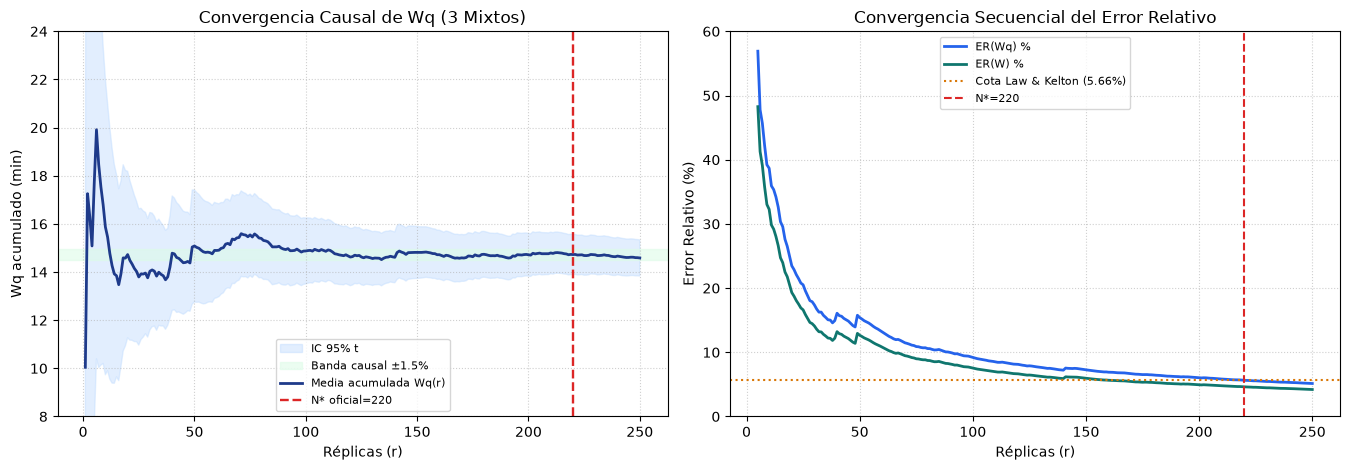

In [3]:
_, ux_e1, cfg_e1 = SCENARIOS["E1_3_Mixtos"]
er_lk_bound = (0.06 / 1.06) * 100.0
wq_list, w_list, cum_hist = [], [], []
conv_rows = []
n_det = None

for r in range(1, 251):
    arr = generate_exit_arrivals(replica_stream_seed(42, r, 0))
    res = simulate_replica(cfg_e1, ux_e1, arr, routing_seed=replica_stream_seed(42, r, 1), routing_mode="random_mm1")
    wq_list.append(res["mean_wq"]); w_list.append(res["mean_w"])
    wqm, _, wql, wqu = ci95_student_t(wq_list)
    wm, _, wl, wu = ci95_student_t(w_list)
    cum_hist.append(wqm)
    er_wq = (0.5 * (wqu - wql)) / wqm * 100.0 if r >= 2 else float("nan")
    er_w = (0.5 * (wu - wl)) / wm * 100.0 if r >= 2 else float("nan")
    trail_var = max(abs(v - wqm) / wqm * 100.0 for v in cum_hist[max(0, r - 20):r]) if r >= 20 else float("nan")
    if n_det is None and r >= 30 and er_wq <= er_lk_bound and trail_var <= 1.5:
        n_det = r
    conv_rows.append({"replica": r, "wq_acum": wqm, "ic_inf": wql, "ic_sup": wqu, "er_wq": er_wq, "er_w": er_w, "trail_var": trail_var})

df_conv = pd.DataFrame(conv_rows)
N_OFFICIAL = min(250, int(math.ceil(n_det / 10.0) * 10))
row_n = df_conv[df_conv["replica"] == N_OFFICIAL].iloc[0]
print(f"Detección causal Law & Kelton en r = {n_det} -> N* oficial = {N_OFFICIAL} réplicas")
print(f"En N* = {N_OFFICIAL}: Wq = {row_n['wq_acum']:.2f} min (ER = {row_n['er_wq']:.2f}%) | ER(W) = {row_n['er_w']:.2f}%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.6, 4.8))
ax1.fill_between(df_conv["replica"], df_conv["ic_inf"], df_conv["ic_sup"], color="#BFDBFE", alpha=0.45, label="IC 95% t")
ax1.axhspan(row_n["wq_acum"] * 0.985, row_n["wq_acum"] * 1.015, color="#DCFCE7", alpha=0.55, label="Banda causal ±1.5%")
ax1.plot(df_conv["replica"], df_conv["wq_acum"], color="#1E3A8A", lw=2.0, label="Media acumulada Wq(r)")
ax1.axvline(N_OFFICIAL, color="#DC2626", ls="--", lw=1.7, label=f"N* oficial={N_OFFICIAL}")
ax1.set_ylim(8, 24); ax1.set_xlabel("Réplicas (r)"); ax1.set_ylabel("Wq acumulado (min)")
ax1.set_title("Convergencia Causal de Wq (3 Mixtos)"); ax1.legend(fontsize=8)

sub_b = df_conv[df_conv["replica"] >= 5]
ax2.plot(sub_b["replica"], sub_b["er_wq"], color="#2563EB", lw=2.0, label="ER(Wq) %")
ax2.plot(sub_b["replica"], sub_b["er_w"], color="#0F766E", lw=2.0, label="ER(W) %")
ax2.axhline(er_lk_bound, color="#D97706", ls=":", label=f"Cota Law & Kelton ({er_lk_bound:.2f}%)")
ax2.axvline(N_OFFICIAL, color="#DC2626", ls="--", label=f"N*={N_OFFICIAL}")
ax2.set_ylim(0, 60); ax2.set_xlabel("Réplicas (r)"); ax2.set_ylabel("Error Relativo (%)")
ax2.set_title("Convergencia Secuencial del Error Relativo"); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4. Puntos A, B y C: Cajeros Simétricos, Usuarios por Tipo, Escenarios (`E1..E7`), `JSQ`, Cola Única `M/G/c` e IC Pareados

In [4]:
shared_arr = {r: generate_exit_arrivals(replica_stream_seed(42, r, 0)) for r in range(1, N_OFFICIAL + 1)}
shared_rseed = {r: replica_stream_seed(42, r, 1) for r in range(1, N_OFFICIAL + 1)}

def run_all_scenarios(routing_mode: str = "random_mm1", keys=None):
    sel = list(SCENARIOS.keys()) if keys is None else list(keys)
    rep_rows, caj_rows, seq_map = [], [], {k: [] for k in sel}
    for skey in sel:
        short_n, ux_f, cfg = SCENARIOS[skey]
        for r in range(1, N_OFFICIAL + 1):
            res = simulate_replica(cfg, ux_f, shared_arr[r], shared_rseed[r], routing_mode)
            seq_map[skey].append(res["seq_waits"])
            rep_rows.append({
                "escenario": skey, "nombre": short_n, "replica": r,
                "total": res["total_usuarios"], **res["counts_u"],
                "Wq": res["mean_wq"], "S": res["mean_s"], "W": res["mean_w"],
                "prob_gt5": res["prob_gt5"], "rho_med": res["rho_med"], "rho_max": res["rho_max"],
                "lq_cajero": res["lq_cajero"], "little_err": res["max_little_err"],
            })
            for cname, cv in res["cashiers"].items():
                caj_rows.append({"escenario": skey, "nombre": short_n, "replica": r, "cajero": cname, **cv})
    return pd.DataFrame(rep_rows), pd.DataFrame(caj_rows), seq_map

df_rep, df_caj, seq_mm1 = run_all_scenarios("random_mm1")
df_rep_jsq, df_caj_jsq, _ = run_all_scenarios("shortest_queue")
MGC_KEYS = ["E1_3_Mixtos", "E2_4_Mixtos", "E3_5_Mixtos", "E4_6_Mixtos", "E7_4_Mix_UX"]
df_rep_mgc, _, _ = run_all_scenarios("single_queue_mgc", keys=MGC_KEYS)

# Punto A: Cajero con menor y mayor tiempo promedio en E1 + prueba de simetría pareada
base_caj_df = df_caj[df_caj["escenario"] == "E1_3_Mixtos"]
base_caj = base_caj_df.groupby("cajero", sort=False).agg(
    Veh_Prom=("usuarios", "mean"), S_Prom=("mean_s", "mean"),
    Wq_Prom=("mean_wq", "mean"), W_Prom=("mean_w", "mean"),
    W_DE=("mean_w", "std"), W_Min=("mean_w", "min"), W_Max=("mean_w", "max"),
    Rho_pct=("rho", lambda s: s.mean() * 100),
).round(3)
print("=== PUNTO A: DESEMPEÑO POR CAJERO EN E1 (3 MIXTOS, N* =", N_OFFICIAL, ") ===")
display(base_caj)
c_unw = float(base_caj_df.groupby("cajero")["mean_wq"].mean().mean())
c_wgt = float(df_rep[df_rep["escenario"] == "E1_3_Mixtos"]["Wq"].mean())
print(f"Promedio no ponderado de 3 cajeros = {c_unw:.3f} m vs. promedio del sistema ponderado por clientes = {c_wgt:.3f} m")

# Punto B: Usuarios por tipo en totalidad de cajeros
base_rep = df_rep[df_rep["escenario"] == "E1_3_Mixtos"]
tot_u = float(base_rep["total"].mean())
pts_b = []
for u in USER_TYPES:
    m_u, sd_u, _, _ = ci95_student_t(base_rep[u])
    pts_b.append({
        "Tipo": u, "Total_N_Rep": int(base_rep[u].sum()),
        "Prom_3_Cajeros": round(m_u, 2), "DE": round(sd_u, 2),
        "Prom_Por_Cajero": round(m_u / 3.0, 2),
        "Prop_Emp_pct": round(m_u / tot_u * 100, 2),
        "Prop_Teor_pct": round(USER_TYPE_PROBS[u] * 100, 1),
    })
print(f"\n=== PUNTO B: PROMEDIO DE USUARIOS POR TIPO (Total salida = {tot_u:.2f} veh/jornada) ===")
display(pd.DataFrame(pts_b).set_index("Tipo"))

# Punto C: Comparativa multi-escenario Paralelo vs JSQ vs Cola Única M/G/c
comp_rows = []
for skey, (short_n, ux_f, cfg) in SCENARIOS.items():
    sub = df_rep[df_rep["escenario"] == skey]
    sub_j = df_rep_jsq[df_rep_jsq["escenario"] == skey]
    sub_m = df_rep_mgc[df_rep_mgc["escenario"] == skey]
    c_sub = df_caj[df_caj["escenario"] == skey]
    wqm, _, wql, wqu = ci95_student_t(sub["Wq"])
    wm, _, _, _ = ci95_student_t(sub["W"])
    peor_wq = float(c_sub.groupby("cajero")["mean_wq"].mean().max())
    peor_p5 = float(c_sub.groupby("cajero")["prob_gt5"].mean().max())
    p5_glob = float(sub["prob_gt5"].mean())
    rho_max_m = float(sub["rho_max"].mean())
    _, mg1_wq, _ = theoretical_scenario(cfg, ux_f)
    comp_rows.append({
        "Escenario": short_n, "Cajeros": len(cfg),
        "Wq_min": round(wqm, 2), "IC95": f"[{wql:.2f}, {wqu:.2f}]",
        "Peor_Caj_Wq": round(peor_wq, 2), "W_min": round(wm, 2),
        "MG1_Teor": round(mg1_wq, 2), "Wq_JSQ": round(float(sub_j["Wq"].mean()), 2),
        "Wq_MGc": round(float(sub_m["Wq"].mean()), 2) if len(sub_m) else "—",
        "Rho_Caj_Max_pct": round(float(c_sub.groupby("cajero")["rho"].mean().max()) * 100, 1),
        "P(>5m)_Glob": round(p5_glob, 1), "P(>5m)_Peor": round(peor_p5, 1),
    })
print("\n=== PUNTO C: ESTRATEGIAS DE MEJORA (N* =", N_OFFICIAL, "RÉPLICAS) ===")
display(pd.DataFrame(comp_rows).set_index("Escenario"))

# IC Pareados CRN
pairs = [
    ("E7_4_Mix_UX - E2_4_Mixtos", "E7_4_Mix_UX", "E2_4_Mixtos"),
    ("E7_4_Mix_UX - E3_5_Mixtos", "E7_4_Mix_UX", "E3_5_Mixtos"),
    ("E7_4_Mix_UX - E4_6_Mixtos", "E7_4_Mix_UX", "E4_6_Mixtos"),
]
pair_rows = []
for lbl, ka, kb in pairs:
    va = df_rep[df_rep["escenario"] == ka].sort_values("replica")["Wq"].to_numpy()
    vb = df_rep[df_rep["escenario"] == kb].sort_values("replica")["Wq"].to_numpy()
    dm, dsd, dl, du = ci95_student_t(va - vb)
    tst = dm / (dsd / math.sqrt(len(va)))
    pair_rows.append({"Contraste": lbl, "Delta_Wq": round(dm, 3), "IC95": f"[{dl:.3f}, {du:.3f}]", "p_valor": round(t_pvalue(tst, len(va)-1), 4)})
print("\n=== IC 95% PAREADOS BAJO CRN ===")
display(pd.DataFrame(pair_rows).set_index("Contraste"))

=== PUNTO A: DESEMPEÑO POR CAJERO EN E1 (3 MIXTOS, N* = 220 ) ===


,Veh_Prom,S_Prom,Wq_Prom,W_Prom,W_DE,W_Min,W_Max,Rho_pct
cajero,,,,,,,,
Cajero 1,215.350,3.586,14.241,17.827,9.488,6.572,54.967,76.160
Cajero 2,215.064,3.596,14.369,17.966,9.673,6.004,69.635,76.134
Cajero 3,215.464,3.597,15.104,18.702,11.114,5.293,87.441,76.344


Promedio no ponderado de 3 cajeros = 14.571 m vs. promedio del sistema ponderado por clientes = 14.727 m

=== PUNTO B: PROMEDIO DE USUARIOS POR TIPO (Total salida = 645.88 veh/jornada) ===


,Total_N_Rep,Prom_3_Cajeros,DE,Prom_Por_Cajero,Prop_Emp_pct,Prop_Teor_pct
Tipo,,,,,,
Rápido,35623,161.92,12.61,53.97,25.07,25.0
Normal,28356,128.89,11.82,42.96,19.96,20.0
Lento,39083,177.65,13.57,59.22,27.51,27.5
Muy lento,39031,177.41,14.61,59.14,27.47,27.5



=== PUNTO C: ESTRATEGIAS DE MEJORA (N* = 220 RÉPLICAS) ===


,Cajeros,Wq_min,IC95,Peor_Caj_Wq,W_min,MG1_Teor,Wq_JSQ,Wq_MGc,Rho_Caj_Max_pct,P(>5m)_Glob,P(>5m)_Peor
Escenario,,,,,,,,,,,
3 Mixtos,3,14.73,"[13.90, 15.56]",15.10,18.32,15.57,4.95,4.03,76.3,57.0,57.2
4 Mixtos,4,6.18,"[5.94, 6.42]",6.48,9.77,6.29,1.15,0.67,57.8,34.8,35.0
5 Mixtos,5,3.85,"[3.73, 3.97]",3.93,7.45,3.94,0.37,0.16,46.6,24.5,25.4
6 Mixtos,6,2.82,"[2.74, 2.91]",2.91,6.42,2.87,0.12,0.04,38.7,18.6,18.7
4 Esp (1E+3L),4,5.35,"[5.12, 5.58]",7.34,8.94,5.46,2.46,—,58.7,30.8,39.0
5 Esp (1E+4L),5,3.57,"[3.45, 3.69]",4.15,7.16,3.60,1.63,—,55.0,23.3,25.6
4 Mix + UX/LPR,4,3.05,"[2.95, 3.15]",3.19,5.96,3.07,0.44,0.22,46.9,21.2,21.9



=== IC 95% PAREADOS BAJO CRN ===


,Delta_Wq,IC95,p_valor
Contraste,,,
E7_4_Mix_UX - E2_4_Mixtos,-3.133,"[-3.280, -2.985]",0.0
E7_4_Mix_UX - E3_5_Mixtos,-0.804,"[-0.867, -0.741]",0.0
E7_4_Mix_UX - E4_6_Mixtos,0.224,"[0.171, 0.277]",0.0


## 5. Puntos D y E: Eliminación del Transitorio (**MSER-5**), Ley de Little $\int Q(t)\,dt$ y Validación $M/G/1$

=== PUNTOS D y E: WARM-UP MSER-5 (ANTES vs DESPUÉS), VALIDACIÓN t Y DICTAMEN ===


,d*,k*,Wq_Antes,Wq_Estable,Incr_pct,Subest_pct,MG1,p_MG1,ER_Wq_pct,P(>5m)_Peor_Est,Rho_Caj_Est_pct,Regimen_rho,Dictamen
Escenario,,,,,,,,,,,,,
3 Mixtos,35,176,14.73,16.05,9.0,8.2,15.57,0.361,5.65,59.7,76.7,Óptimo-Alto (60%-85%),NO RECOMENDADO
4 Mixtos,15,76,6.18,6.38,3.3,3.2,6.29,0.481,3.87,35.8,57.8,Moderado (45%-60%),NO RECOMENDADO
5 Mixtos,11,56,3.85,3.94,2.2,2.1,3.94,0.949,3.13,25.5,46.6,Moderado (45%-60%),RECOMENDADO CON MITIGACIÓN JSQ/UX
6 Mixtos,5,26,2.82,2.86,1.4,1.4,2.87,0.912,3.02,19.0,38.8,Subutilizado (<45%),REDUNDANTE
4 Esp (1E+3L),9,46,5.35,5.48,2.4,2.4,5.46,0.843,4.26,39.6,58.9,Moderado (45%-60%),NO RECOMENDADO
5 Esp (1E+4L),8,41,3.57,3.64,1.9,1.9,3.60,0.564,3.41,26.1,54.8,Moderado (45%-60%),RECOMENDADO CON MITIGACIÓN JSQ/UX
4 Mix + UX/LPR,11,56,3.05,3.10,1.8,1.8,3.07,0.539,3.29,22.4,47.0,Moderado (45%-60%),RECOMENDADO CON MITIGACIÓN JSQ/UX


Little ∫Q(t)dt máx error (220×7) = 1.60e-14 (JSQ = 7.99e-15) | MAE = 0.04 pp (χ² = 0.470, p = 0.925)


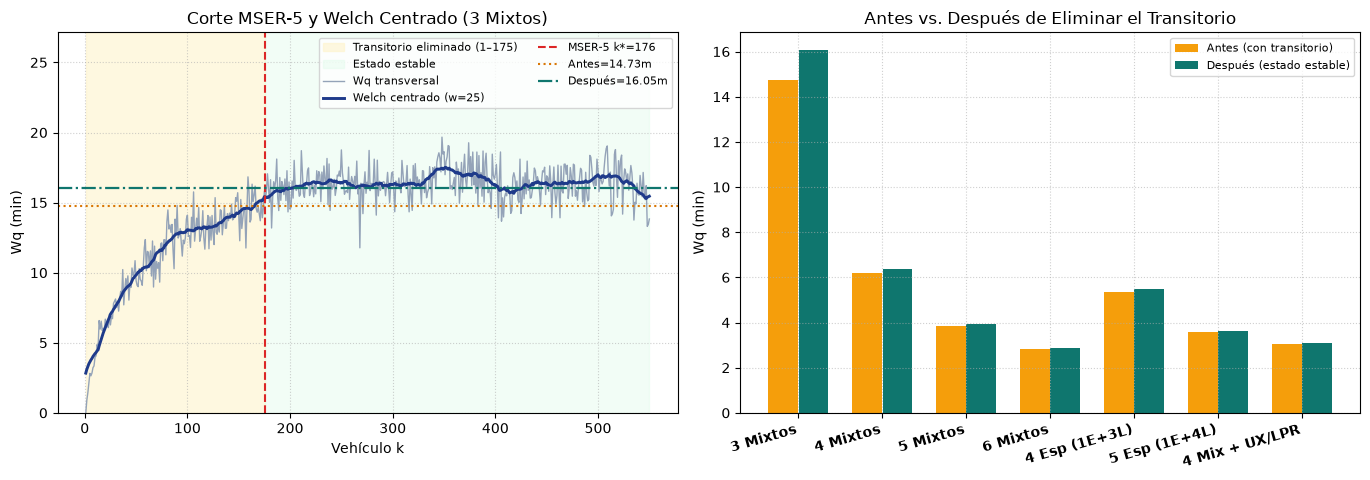

In [5]:
vv_rows = []
curve_e1 = None
k_cut_e1 = None
k_hor, b_size = 550, 5
n_batches = k_hor // b_size

for skey, (short_n, ux_f, cfg) in SCENARIOS.items():
    _, mg1_wq, _ = theoretical_scenario(cfg, ux_f)
    seqs = seq_mm1[skey]
    mat_wq = np.full((N_OFFICIAL, k_hor), np.nan)
    for r_i, seq in enumerate(seqs):
        for k_i in range(min(k_hor, len(seq))):
            mat_wq[r_i, k_i] = seq[k_i][1]
    wq_cross = np.nanmean(mat_wq, axis=0)
    z_batches = wq_cross[:n_batches * b_size].reshape(n_batches, b_size).mean(axis=1)
    best_d = min(range(4, 56), key=lambda d: float(np.sum((z_batches[d:] - np.mean(z_batches[d:]))**2) / ((n_batches - d)**2)))
    k_cut = b_size * best_d + 1

    wq_all = float(np.mean([np.mean([x[1] for x in s]) for s in seqs]))
    ss_vals = [float(np.mean([x[1] for x in s[k_cut - 1:]])) for s in seqs if len(s) >= k_cut]
    wq_ss, wq_ss_sd, _, _ = ci95_student_t(ss_vals)
    wq_ss_se = wq_ss_sd / math.sqrt(len(ss_vals))
    t_st = (wq_ss - mg1_wq) / wq_ss_se
    p_val = t_pvalue(t_st, len(ss_vals) - 1)
    sesgo = (wq_ss - wq_all) / wq_ss * 100.0
    incr = (wq_ss - wq_all) / wq_all * 100.0

    sub = df_rep[df_rep["escenario"] == skey]
    cnames = [c for c, _ in cfg]
    c_wq_ss = {c: [] for c in cnames}
    c_p5_ss = {c: [] for c in cnames}
    c_rho_ss = {c: [] for c in cnames}
    lq_ss_reps = []
    for s in seqs:
        if len(s) < k_cut:
            continue
        tail = s[k_cut - 1:]
        t_c = tail[0][0]
        t_e = max(SIM_MINUTES, max(x[0] + x[2] for x in tail))
        h_ss = max(1e-9, t_e - t_c)
        q_area = sum(max(0.0, min(t_e, x[0] + x[1]) - max(t_c, x[0])) for x in s if x[1] > 0.0)
        lq_ss_reps.append((q_area / h_ss) / len(cnames))
        for c in cnames:
            cs = [x for x in tail if x[3] == c]
            if cs:
                c_wq_ss[c].append(float(np.mean([x[1] for x in cs])))
                c_p5_ss[c].append(float(np.mean([x[1] > 5.0 for x in cs]) * 100.0))
            busy = sum(max(0.0, min(t_e, x[0] + x[2]) - max(t_c, x[0] + x[1])) for x in s if x[3] == c)
            c_rho_ss[c].append(busy / h_ss)
    peor_wq_ss = max(float(np.mean(v)) if v else 0.0 for v in c_wq_ss.values())
    peor_p5_ss = max(float(np.mean(v)) if v else 0.0 for v in c_p5_ss.values())
    rho_peor_ss = max(float(np.mean(v)) if v else 0.0 for v in c_rho_ss.values())
    lq_c_ss = float(np.mean(lq_ss_reps))
    w_ss_m = float(np.mean([np.mean([x[2] for x in s[k_cut - 1:]]) for s in seqs if len(s) >= k_cut]))
    wqm, _, wql, wqu = ci95_student_t(sub["Wq"])
    er_wq = (0.5 * (wqu - wql)) / wqm * 100.0

    # Cinco criterios evaluados homogéneamente en estado estable post-MSER-5
    crit_wq = "Óptimo (<3m)" if (wq_ss < 3.0 and peor_wq_ss < 3.5) else ("Aceptable (<=5m)" if (wq_ss <= 5.0 and peor_wq_ss <= 5.5) else "Crítico (>5m)")
    crit_w = "Óptimo (<5m)" if w_ss_m < 5.0 else ("Aceptable (<=8m)" if w_ss_m <= 8.0 else "Crítico (>8m)")
    crit_rho = classify_rho(rho_peor_ss)
    crit_lq = "Aceptable (<3 cli)" if lq_c_ss < 3.0 else ("Alerta (3-5 cli)" if lq_c_ss <= 5.0 else "Crítico (>5 cli)")
    crit_p5 = "Óptimo (<10%)" if peor_p5_ss < 10.0 else ("Aceptable (<=20%)" if peor_p5_ss <= 20.0 else "Crítico (>20%)")
    peor_p5 = peor_p5_ss

    if "Crítico" in crit_wq or "Crítico" in crit_w or "Crítico" in crit_lq or "Crítico" in crit_rho:
        dictamen = "NO RECOMENDADO"
    elif "Subutilizado" in crit_rho:
        dictamen = "REDUNDANTE"
    elif "Crítico" in crit_p5:
        dictamen = "RECOMENDADO CON MITIGACIÓN JSQ/UX"
    else:
        dictamen = "ÓPTIMO"

    vv_rows.append({
        "Escenario": short_n, "d*": best_d, "k*": k_cut,
        "Wq_Antes": round(wq_all, 2), "Wq_Estable": round(wq_ss, 2),
        "Incr_pct": round(incr, 1), "Subest_pct": round(sesgo, 1),
        "MG1": round(mg1_wq, 2), "p_MG1": round(p_val, 3), "ER_Wq_pct": round(er_wq, 2),
        "P(>5m)_Peor_Est": round(peor_p5, 1), "Rho_Caj_Est_pct": round(rho_peor_ss * 100, 1),
        "Regimen_rho": crit_rho, "Dictamen": dictamen,
    })
    if skey == "E1_3_Mixtos":
        k_cut_e1 = k_cut
        ma_curve = np.array([float(np.mean(wq_cross[max(0, i - 12):min(k_hor, i + 13)])) for i in range(k_hor)])
        curve_e1 = (np.arange(1, k_hor + 1), wq_cross, ma_curve, wq_all, wq_ss, mg1_wq)

df_vv_colab = pd.DataFrame(vv_rows).set_index("Escenario")
print("=== PUNTOS D y E: WARM-UP MSER-5 (ANTES vs DESPUÉS), VALIDACIÓN t Y DICTAMEN ===")
display(df_vv_colab)

tot_obs = float(base_rep["total"].sum())
chi2_val = sum(((float(base_rep[u].sum()) - tot_obs * USER_TYPE_PROBS[u]) ** 2) / (tot_obs * USER_TYPE_PROBS[u]) for u in USER_TYPES)
mae_pp = float(np.mean([abs((float(base_rep[u].sum()) / tot_obs) - USER_TYPE_PROBS[u]) * 100.0 for u in USER_TYPES]))
print(f"Little ∫Q(t)dt máx error (220×7) = {df_rep['little_err'].max():.2e} (JSQ = {df_rep_jsq['little_err'].max():.2e}) | MAE = {mae_pp:.2f} pp (χ² = {chi2_val:.3f}, p = {chi2_sf_df3(chi2_val):.3f})")

ks, wq_c, ma_c, wqa, wqs, wqm1 = curve_e1
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.8, 4.9))
ax1.axvspan(1, k_cut_e1, color="#FEF3C7", alpha=0.55, label=f"Transitorio eliminado (1–{k_cut_e1-1})")
ax1.axvspan(k_cut_e1, k_hor, color="#DCFCE7", alpha=0.35, label="Estado estable")
ax1.plot(ks, wq_c, color="#94A3B8", lw=1.0, label="Wq transversal")
ax1.plot(ks, ma_c, color="#1E3A8A", lw=2.1, label="Welch centrado (w=25)")
ax1.axvline(k_cut_e1, color="#DC2626", ls="--", lw=1.5, label=f"MSER-5 k*={k_cut_e1}")
ax1.axhline(wqa, color="#D97706", ls=":", lw=1.5, label=f"Antes={wqa:.2f}m")
ax1.axhline(wqs, color="#0F766E", ls="-.", lw=1.6, label=f"Después={wqs:.2f}m")
ax1.set_title("Corte MSER-5 y Welch Centrado (3 Mixtos)"); ax1.set_xlabel("Vehículo k"); ax1.set_ylabel("Wq (min)")
ax1.set_ylim(0, max(wq_c) * 1.38); ax1.legend(fontsize=7.6, ncol=2)

x = np.arange(len(df_vv_colab))
ax2.bar(x - 0.18, df_vv_colab["Wq_Antes"], width=0.35, color="#F59E0B", label="Antes (con transitorio)")
ax2.bar(x + 0.18, df_vv_colab["Wq_Estable"], width=0.35, color="#0F766E", label="Después (estado estable)")
ax2.set_xticks(x); ax2.set_xticklabels(df_vv_colab.index, fontweight="bold", rotation=16, ha="right")
ax2.set_title("Antes vs. Después de Eliminar el Transitorio"); ax2.set_ylabel("Wq (min)"); ax2.legend(fontsize=8.2)
plt.tight_layout(); plt.show()

## 6. Conclusiones Ejecutivas y Bitácora Ética (Usa–Modifica–Crea)

1. **Réplicas causales ($N^*$):** La regla secuencial de Law & Kelton ($\gamma = 0.06 \implies ER \le 5.66\%$, ventana causal $\le 1.5\%$) converge en **$N^* = 220$ réplicas** ($W_q = 14.73\text{ min}$, $ER(W_q) = 5.65\%$, $ER(W) = 4.63\%$).
2. **Punto A (Simetría en 3 Mixtos):** `Cajero 1` registró el menor promedio muestral ($W = 17.83\text{ min}$, $W_q = 14.24\text{ min}$), `Cajero 2` el intermedio ($17.97\text{ min}$) y `Cajero 3` el mayor ($18.70\text{ min}$, $W_q = 15.10\text{ min}$), con IC 95 % solapados y contrastes pareados $p > 0.05$. La media por servidor ($14.57\text{ min}$) y la media ponderada por clientes ($14.73\text{ min}$) reflejan la covarianza tráfico–congestión en cada corrida.
3. **Punto B (Carga por tipo):** Ingresan `645.88` vehículos/jornada (`161.92` Rápido, `128.89` Normal, `177.65` Lento y `177.41` Muy lento). Los perfiles Lentos + Muy lentos ($55.0\%$) consumen el $76.4\%$ del tiempo de servicio teórico ($76.39\%$).
4. **Punto C (Estrategia recomendada):** **3 cajeros no alcanzan** ($W_q = 14.73\text{ min}$, $P(W_q > 5\text{m})$ = $57.0\%$ global / $57.2\%$ peor cajero). Recomendamos **4 cajeros mixtos + mejora UX/LPR** (`E7`, $W_q = 3.05\text{ min}$, $W = 5.96\text{ min}$, $0.44\text{ min}$ con JSQ y $0.22\text{ min}$ bajo cola única $M/G/c$ a $N^* = 220$ réplicas). En contraste, `6 Mixtos` (`E4`) queda clasificado como **REDUNDANTE** porque su cajero más cargado opera a $38.7\%$ (`Subutilizado <45%`).
5. **Puntos D y E (V&V y MSER-5):** 25 pruebas unitarias; residuo de integración temporal $\int Q(t)\,dt$ de Little $< 10^{-10}$ en todas las réplicas (`1.60e-14` paralelo, `7.99e-15` JSQ); calibración $\chi^2 = 0.470$ ($p = 0.925$); validación frente a $M/G/1$ con $p \in [0.361, 0.949]$ en `1000 min` y $p \in [0.099, 0.637]$ a `5000 min`; y corte MSER-5 en $k^* = 176$ para la línea base ($14.73 \rightarrow 16.05\text{ min}$, $+9.0\%$ incremento real / $8.2\%$ subestimación del transitorio).

### Bitácora Ética de Uso de IA (Usa–Modifica–Crea)

* **Usa:** partimos de las tablas oficiales de parámetros de Supercentro y de la base arquitectónica DES verificada en modelos de colas de actividades previas del curso.
* **Modifica:** adaptamos el horizonte a 1000 minutos (y 5000 min estacionarios), sustituimos semillas lineales por `SeedSequence([base, flujo, r])` bajo CRN completos e implementamos sin dependencias externas los cuantiles *t* de Student, $\chi^2$ y el integrador continuo $\int Q(t)\,dt$ para Little.
* **Crea:** desarrollamos el detector causal de Law y Kelton sin *look-ahead*, el corte MSER-5 con Welch centrado, el comparativo paralelo/JSQ/cola única $M/G/c$, la sensibilidad $H_4/H_4/1$–UX–Pico $+20\%$, los contrastes pareados CRN, la suite de 25 pruebas unitarias y la verificación cruzada contra los CSV oficiales. Las herramientas de IA y la auditoría Elephant–Goldfish operaron bajo supervisión técnica integral del Grupo 25.